In [1]:
from sklearn.model_selection import train_test_split
from sklearn import datasets

import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd

plt.style.use("ggplot")

## Uncertainty estimates from classifiers

- Classifier predictions often require understanding not just the predicted class but also the certainty of the prediction.  
- Different mistakes (false positives vs. false negatives) have varying real-world consequences.  
  - Example: In medical testing for cancer:  
    - A false positive leads to additional tests.  
    - A false negative means a serious disease might go untreated.  
- Scikit-learn provides two functions to estimate uncertainty in classifiers:  
  - `decision_function`  
  - `predict_proba`  
- Most classifiers support at least one of these functions, and many support both.  

### Very important

Please read [this page](https://scikit-learn.org/stable/modules/calibration.html) from scikit-learn regarding uncertainty quantification. Especially this part:

"Well calibrated classifiers are probabilistic classifiers for which the output of the predict_proba method can be directly interpreted as a confidence level. For instance, a well calibrated (binary) classifier should classify the samples such that among the samples to which it gave a predict_proba value close to, say, 0.8, approximately 80% actually belong to the positive class."



In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# let's take the example of logistic regression which we discussed above

iris = datasets.load_iris()

# first 100 samples (0 = Setosa, 1 = Versicolor)
X = iris.data[:100, :2]
y = iris.target[:100]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=9)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

Accuracy: 0.95


## Decision function

The values of decision function encode how strongly the model `believes' a data point to belong to the  “positive” class, in this case class 1. Positive values indicate a preference for the positive class, and negative values indicate a preference for the “negative” (other) class. (Guido & Mueller)


Decision function:
 [ 5.01399674 -4.00641672 -4.36799334  7.44675926 -2.78794936 -2.42011444
 -1.93314472 -1.32286799  1.47981556  4.15919209  0.74205962 -2.78586326
 -5.4631537  -0.83798436  1.72225737  4.280413   -4.24885853 -4.36799334
 -3.88102362 -2.05436562]
[1 0 0 1 0 0 0 0 1 1 0 0 0 0 1 1 0 0 0 0]


Text(0, 0.5, 'Decision function')

Binary decision function:
 [ True False False  True False False False False  True  True  True False
 False False  True  True False False False False]
Predictions:
 [1 0 0 1 0 0 0 0 1 1 1 0 0 0 1 1 0 0 0 0]
Actual:
 [1 0 0 1 0 0 0 0 1 1 0 0 0 0 1 1 0 0 0 0]


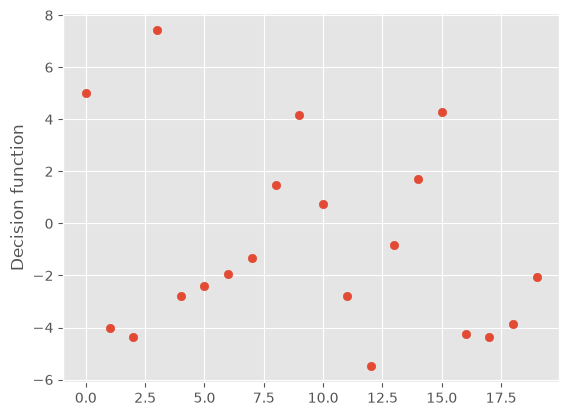

In [3]:
print(f"Decision function:\n {model.decision_function(X_test)}")
print(y_test)
plt.scatter(np.arange(0, len(model.predict(X_test))), model.decision_function(X_test))
plt.ylabel("Decision function")
print(f"Binary decision function:\n {model.decision_function(X_test) > 0}")
print(f"Predictions:\n {model.predict(X_test)}")
print(f"Actual:\n {y_test}")
pass

### predicted probabilities

- The output of `predict_proba` is a probability for each class.
- Probabilities for the two classes in classification always sum to 1.  
- The class with a probability above 50% is the one that is predicted.  
- In practice, classifiers are usually relatively certain about their predictions for most points.  
- The accuracy of uncertainty estimates depends on the model and its parameters:  
  - Overfitted models: Tend to make overly certain predictions, even when incorrect.  
  - Simpler models: Often show greater uncertainty in their predictions.  
- A model is considered calibrated if its reported uncertainty matches its actual accuracy:  
  - For example, a prediction with 70% certainty is correct 70% of the time.  

First few predicted probabilities:
[[0.00660044 0.99339956]
 [0.98212678 0.01787322]
 [0.98748203 0.01251797]]


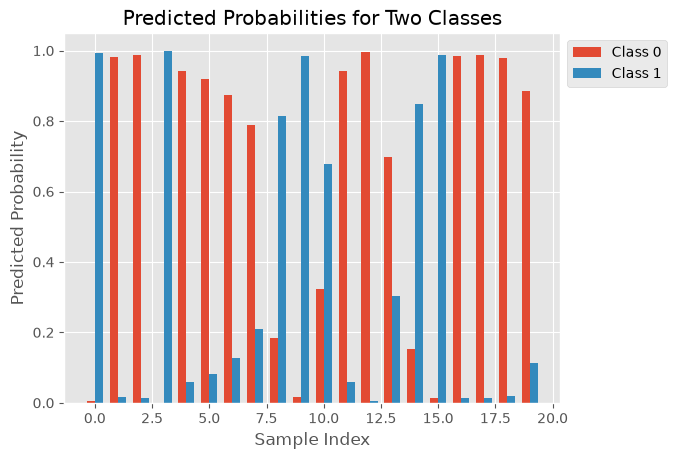

In [4]:
probabilities = model.predict_proba(X_test)
print(f"First few predicted probabilities:\n{probabilities[:3]}")

# plot them

x = np.arange(len(probabilities))
width = 0.35
plt.bar(x - width / 2, probabilities[:, 0], width, label="Class 0")
plt.bar(x + width / 2, probabilities[:, 1], width, label="Class 1")

# Add labels, title, and legend
plt.xlabel("Sample Index")
plt.ylabel("Predicted Probability")
plt.title("Predicted Probabilities for Two Classes")
# plt.xticks(x)
plt.legend(bbox_to_anchor=[1, 1])
pass;

In [5]:
# this can be extended to multiclass classifications. the code works as expected

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# let's take the example of logistic regression which we discussed above

iris = datasets.load_iris()

X = iris.data  # [:100, :2]
y = iris.target  # [:100]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=9)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print(f"First few decision function:\n {model.decision_function(X_test[:3])}")

probabilities = model.predict_proba(X_test)
print(f"First few predicted probabilities:\n{probabilities[:3]}")

pass;

Accuracy: 1.00
First few decision function:
 [[-7.6536117   1.76821981  5.88539188]
 [-1.58337136  1.93907857 -0.35570721]
 [-5.45707804  1.24869262  4.20838542]]
First few predicted probabilities:
[[1.29737946e-06 1.60293700e-02 9.83969333e-01]
 [2.61229287e-02 8.84713053e-01 8.91640180e-02]
 [6.03071508e-05 4.92774253e-02 9.50662268e-01]]


In [6]:
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

## Accuracy score in Scikit

- Accuracy = correct_classification/ all classification (for multiclass classifications)
- $\texttt{accuracy}(y, \hat{y}) = \frac{1}{n_\text{samples}} \sum_{i=0}^{n_\text{samples}-1} 1(\hat{y}_i = y_i)$

In [7]:
y_true = [0, 0, 1, 1, 1, 0]
y_pred = [0, 1, 1, 0, 1, 1]
accuracy_score(y_true, y_pred)

0.5

## Confusion Matrix

From [Scikit documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html):

Compute confusion matrix to evaluate the accuracy of a classification.

By definition a confusion matrix $C$ is such that $C_{i,j}$ is equal to the number of observations known to be in group and $i$ predicted to be in group $j$.

Thus in binary classification, the count of true negatives is $C_{0,0}$, false negatives is $C_{1,0}$, true positives is $C_{1,1}$ and false positives is $C_{0,1}$.


**Notice that conventions can differ, so please check your package to know which element indicates which quantity.**

![](images/conf-mat.png)
![](images/conf-mat1.png)

[Image source: Wikipedia](https://en.wikipedia.org/wiki/Confusion_matrix)

In [ ]:
# a toy example of confusion matrix. scikit uses a different convention! https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

y_true
y_pred

confusion_matrix(y_true, y_pred)

[0, 0, 1, 1, 1, 0]

[0, 1, 1, 0, 1, 1]

array([[1, 2],
       [1, 2]])

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

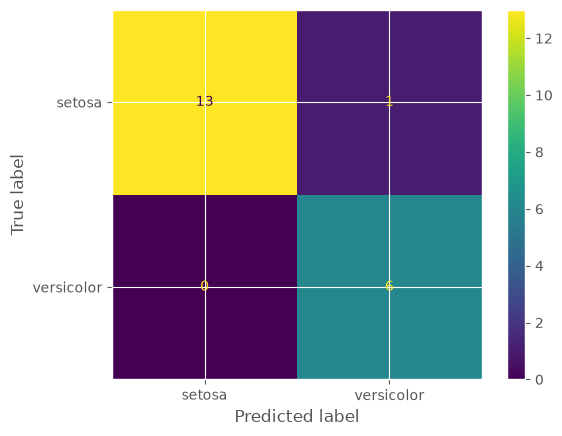

In [9]:
# confusion matrix example for iris dataset with only two properties and two classes (binary classification)
iris = datasets.load_iris()

# first 100 samples (0 = Setosa, 1 = Versicolor)
X = iris.data[:100, :2]
y = iris.target[:100]
class_names = iris.target_names[:2]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=9)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=class_names)
disp.plot()

### Generalizing to multi-class classifications:

confusion matrix example for full iris dataset

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

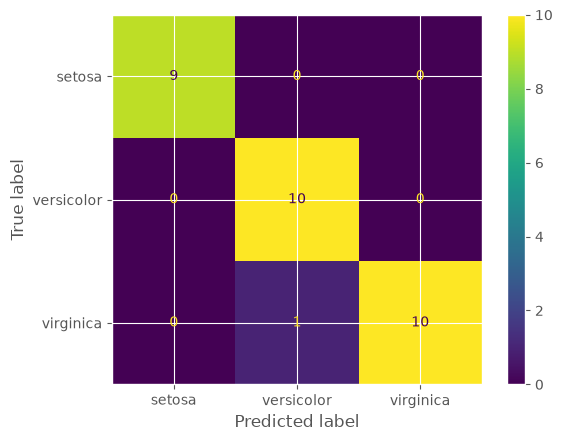

In [10]:
iris = datasets.load_iris()
X = iris.data
y = iris.target
class_names = iris.target_names

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=class_names)
disp.plot()